In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance.csv


In [3]:
df = pd.read_csv("StudentsPerformance.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 8)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:
print(df.describe())

       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.16308      14.600192      15.195657
min       0.00000      17.000000      10.000000
25%      57.00000      59.000000      57.750000
50%      66.00000      70.000000      69.000000
75%      77.00000      79.000000      79.000000
max     100.00000     100.000000     100.000000


In [7]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
df.columns = [
    "gender",
    "race_ethnicity",
    "parental_education",
    "lunch",
    "test_preparation",
    "math_score",
    "reading_score",
    "writing_score"
]

print(df.head())

   gender race_ethnicity  parental_education         lunch test_preparation  \
0  female        group B   bachelor's degree      standard             none   
1  female        group C        some college      standard        completed   
2  female        group B     master's degree      standard             none   
3    male        group A  associate's degree  free/reduced             none   
4    male        group C        some college      standard             none   

   math_score  reading_score  writing_score  
0          72             72             74  
1          69             90             88  
2          90             95             93  
3          47             57             44  
4          76             78             75  


In [10]:
df = df.drop_duplicates()

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("Missing Values:")
print(df.isnull().sum())

print("Cleaned Dataset Shape:", df.shape)

Missing Values:
gender                0
race_ethnicity        0
parental_education    0
lunch                 0
test_preparation      0
math_score            0
reading_score         0
writing_score         0
dtype: int64
Cleaned Dataset Shape: (1000, 8)


In [11]:
df["average_score"] = df[
    ["math_score", "reading_score", "writing_score"]
].mean(axis=1)

print(df.head())

   gender race_ethnicity  parental_education         lunch test_preparation  \
0  female        group B   bachelor's degree      standard             none   
1  female        group C        some college      standard        completed   
2  female        group B     master's degree      standard             none   
3    male        group A  associate's degree  free/reduced             none   
4    male        group C        some college      standard             none   

   math_score  reading_score  writing_score  average_score  
0          72             72             74      72.666667  
1          69             90             88      82.333333  
2          90             95             93      92.666667  
3          47             57             44      49.333333  
4          76             78             75      76.333333  


In [12]:
print(df["average_score"].describe())

count    1000.000000
mean       67.770667
std        14.257326
min         9.000000
25%        58.333333
50%        68.333333
75%        77.666667
max       100.000000
Name: average_score, dtype: float64


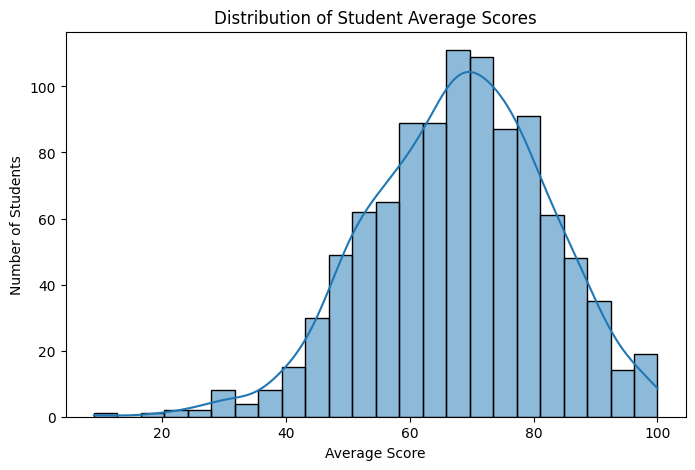

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["average_score"],
    kde=True
)

plt.title("Distribution of Student Average Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")

plt.savefig("average_score_distribution.png")
plt.show()

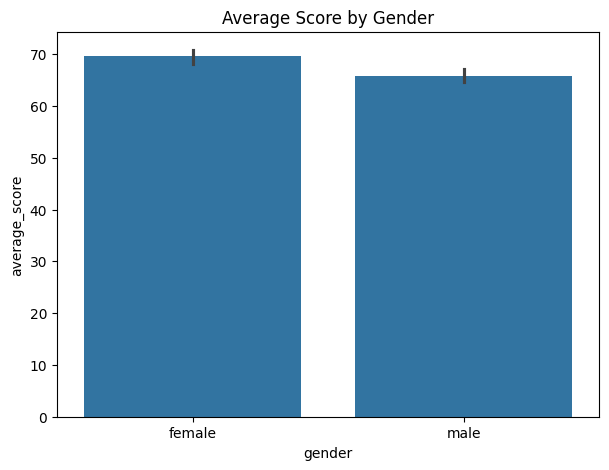

In [14]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="gender",
    y="average_score"
)

plt.title("Average Score by Gender")
plt.savefig("gender_performance.png")
plt.show()

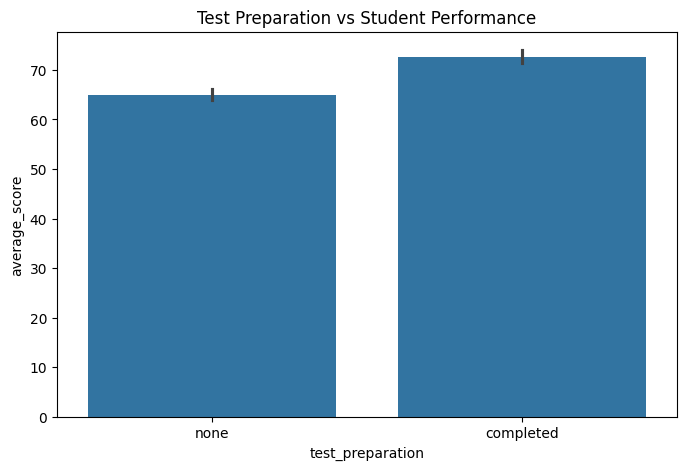

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="test_preparation",
    y="average_score"
)

plt.title("Test Preparation vs Student Performance")
plt.savefig("test_preparation_analysis.png")
plt.show()

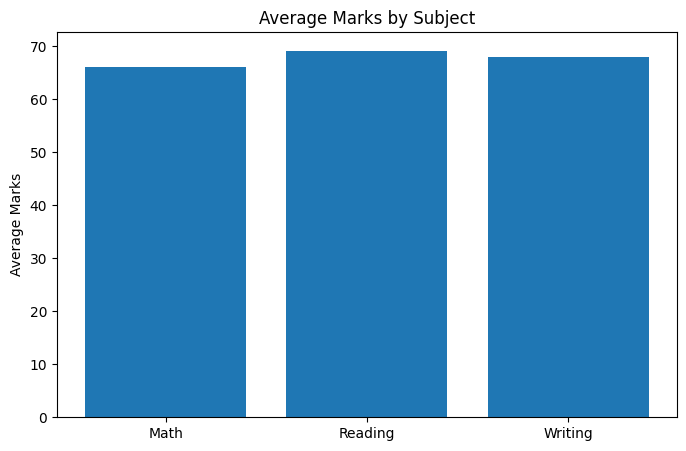

In [16]:
plt.figure(figsize=(8, 5))

subjects = [
    df["math_score"].mean(),
    df["reading_score"].mean(),
    df["writing_score"].mean()
]

plt.bar(
    ["Math", "Reading", "Writing"],
    subjects
)

plt.title("Average Marks by Subject")
plt.ylabel("Average Marks")

plt.savefig("subject_score_comparison.png")
plt.show()

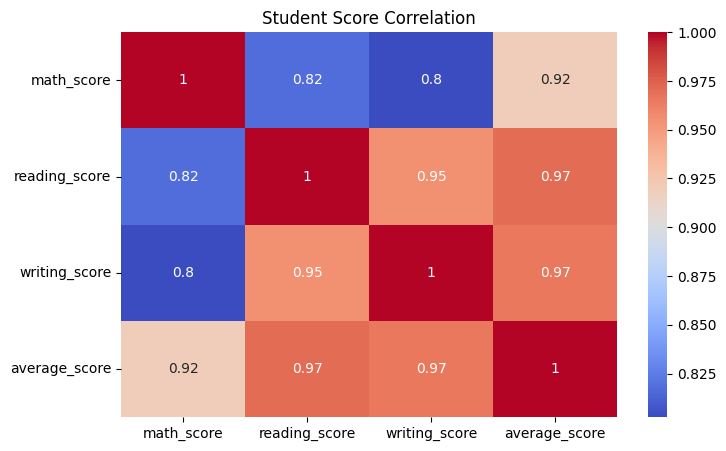

In [17]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[
        ["math_score", "reading_score",
         "writing_score", "average_score"]
    ].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Student Score Correlation")

plt.savefig("correlation_heatmap.png")
plt.show()

In [18]:
X = df[
    [
        "gender",
        "race_ethnicity",
        "parental_education",
        "lunch",
        "test_preparation"
    ]
]

y = df["average_score"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   gender race_ethnicity  parental_education         lunch test_preparation
0  female        group B   bachelor's degree      standard             none
1  female        group C        some college      standard        completed
2  female        group B     master's degree      standard             none
3    male        group A  associate's degree  free/reduced             none
4    male        group C        some college      standard             none

Target:
0    72.666667
1    82.333333
2    92.666667
3    49.333333
4    76.333333
Name: average_score, dtype: float64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 800
Testing Records: 200


In [20]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [21]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

print("Model created successfully!")

Model created successfully!


In [22]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [23]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[87.         64.         75.         74.66666667 81.66666667 78.
 67.33333333 59.         77.33333333 48.66666667]

Predicted Values:
[67.30361801 70.49831217 62.2416746  57.11210317 80.06941667 59.95296825
 67.91002381 60.806      60.21027226 70.10107419]


In [24]:
predictions = pd.DataFrame({
    "Actual_Average_Score": y_test.values,
    "Predicted_Average_Score": y_pred
})

predictions["Difference"] = (
    predictions["Actual_Average_Score"]
    - predictions["Predicted_Average_Score"]
).abs()

print(predictions.head(10))

   Actual_Average_Score  Predicted_Average_Score  Difference
0             87.000000                67.303618   19.696382
1             64.000000                70.498312    6.498312
2             75.000000                62.241675   12.758325
3             74.666667                57.112103   17.554563
4             81.666667                80.069417    1.597250
5             78.000000                59.952968   18.047032
6             67.333333                67.910024    0.576690
7             59.000000                60.806000    1.806000
8             77.333333                60.210272   17.123061
9             48.666667                70.101074   21.434408


In [25]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 11.4884482992557
MSE: 219.77398895896843
RMSE: 14.824776185796818
R2 Score: -0.02522511964615326


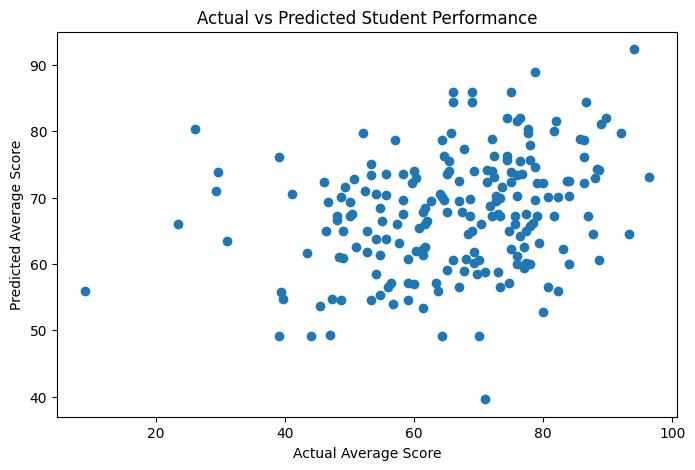

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Average Score")
plt.ylabel("Predicted Average Score")

plt.title("Actual vs Predicted Student Performance")

plt.savefig("actual_vs_predicted.png")
plt.show()

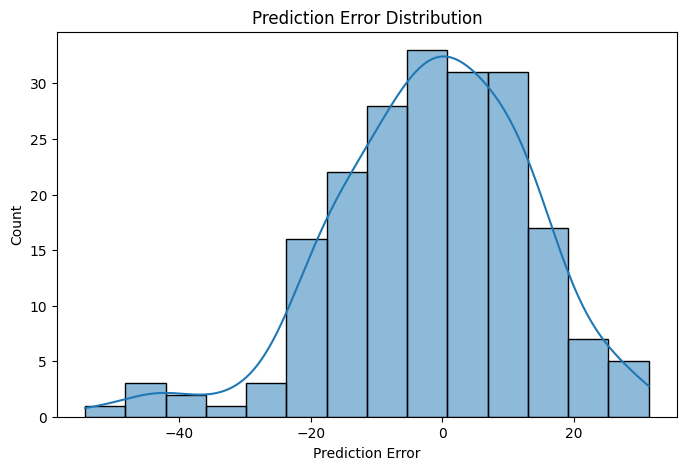

In [27]:
errors = y_test.values - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(errors, kde=True)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")

plt.savefig("prediction_error_distribution.png")
plt.show()

In [28]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    model.named_steps["regressor"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                                              Feature  Importance
14                        categorical__lunch_standard    0.098802
15            categorical__test_preparation_completed    0.082585
13                    categorical__lunch_free/reduced    0.081891
16                 categorical__test_preparation_none    0.070099
9         categorical__parental_education_high school    0.062198
3                 categorical__race_ethnicity_group B    0.060539
1                            categorical__gender_male    0.059370
8   categorical__parental_education_bachelor's degree    0.057044
6                 categorical__race_ethnicity_group E    0.056648
5                 categorical__race_ethnicity_group D    0.052729
12   categorical__parental_education_some high school    0.050971
4                 categorical__race_ethnicity_group C    0.049956
0                          categorical__gender_female    0.049673
7   categorical__parental_education_associate's de...    0.047802
2         

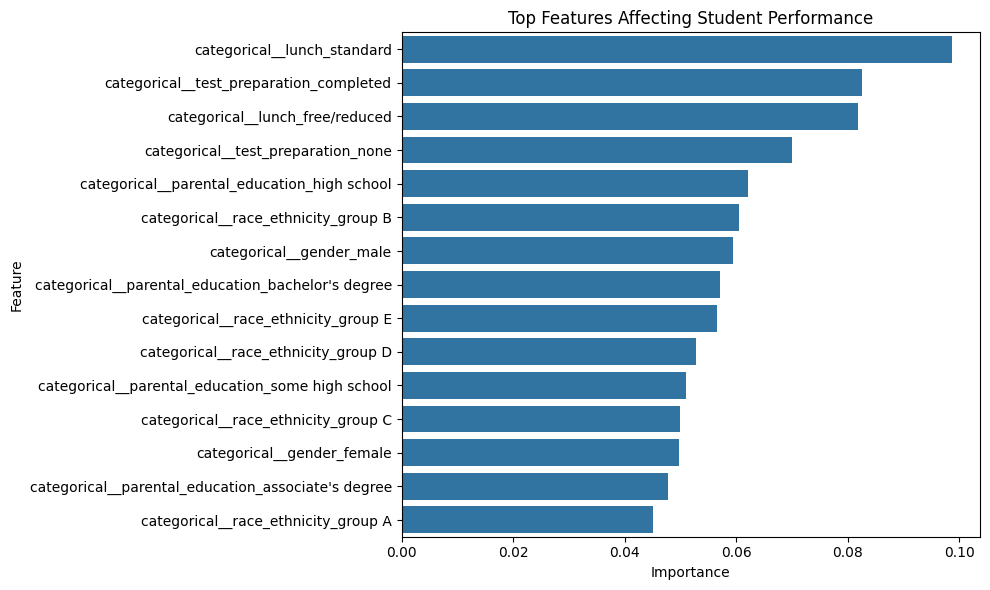

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top Features Affecting Student Performance")
plt.tight_layout()

plt.savefig("feature_importance.png")
plt.show()

In [30]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],
    "Value": [
        mae,
        mse,
        rmse,
        r2
    ]
})

print(evaluation_summary)

     Metric       Value
0       MAE   11.488448
1       MSE  219.773989
2      RMSE   14.824776
3  R2 Score   -0.025225


In [31]:
df.to_csv(
    "cleaned_student_performance.csv",
    index=False
)

print("Cleaned dataset exported!")

Cleaned dataset exported!


In [32]:
X.to_csv("student_features.csv", index=False)

y.to_csv("student_target.csv", index=False)

print("Features and target exported!")

Features and target exported!


In [33]:
predictions.to_csv(
    "student_predictions.csv",
    index=False
)

print("Predictions exported!")

Predictions exported!


In [34]:
evaluation_summary.to_csv(
    "evaluation_summary.csv",
    index=False
)

print("Evaluation summary exported!")

Evaluation summary exported!


In [35]:
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance exported!")

Feature importance exported!


In [36]:
joblib.dump(
    model,
    "student_performance_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [37]:
loaded_model = joblib.load(
    "student_performance_model.joblib"
)

sample_prediction = loaded_model.predict(
    X_test.iloc[:5]
)

print("Sample Predictions:")
print(sample_prediction)

Sample Predictions:
[67.30361801 70.49831217 62.2416746  57.11210317 80.06941667]


In [38]:
from google.colab import files
files.download("cleaned_student_performance.csv")
files.download("student_features.csv")
files.download("student_target.csv")
files.download("student_predictions.csv")
files.download("evaluation_summary.csv")
files.download("feature_importance.csv")
files.download("student_performance_model.joblib")
files.download("average_score_distribution.png")
files.download("gender_performance.png")
files.download("test_preparation_analysis.png")
files.download("subject_score_comparison.png")
files.download("correlation_heatmap.png")
files.download("actual_vs_predicted.png")
files.download("prediction_error_distribution.png")
files.download("feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (20 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>